# Chapitre 12 - Cours 7 : vie privée, pistage et surveillance

Le cours précédent portait sur l'usage des données pour **décider** à propos des
personnes. Celui-ci remonte d'un cran : la **collecte** elle-même pose problème. Quelle
relation lie l'organisation qui collecte et les personnes dont elle collecte les
données ? Le notebook couvre la partie *Privacy and Tracking* (sous-sections *Surveillance*, *Consent and freedom of choice*, *Privacy and use of data*, *Data as assets and power*, *Remembering the Industrial Revolution*, *Legislation and self-regulation*),
qui clôt le livre.

Comme au cours précédent, toutes les données sont **synthétiques** : une population
fictive de 100 000 personnes (code postal, date de naissance, sexe, quelques
attributs), générée par `et.make_population`. Elle suffit à montrer pourquoi
« anonymiser » est si difficile.

**Plan.**

1. Du service rendu au pistage.
2. Surveillance : l'anonymat est une illusion.
3. Consentement et liberté de choix.
4. Vie privée et usage des données.
5. Les données, un actif toxique et une source de pouvoir.
6. Se souvenir de la révolution industrielle.
7. Législation et autorégulation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import ethics as et
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)

## 1. Du service rendu au pistage (section *Privacy and Tracking*)

Quand un système ne stocke que ce que l'utilisateur y a saisi, pour qu'il le stocke et
le traite comme il l'a demandé, le système **rend un service** : l'utilisateur est le
client. Quand l'activité de l'utilisateur est enregistrée **en passant**, comme effet de
bord de ce qu'il fait, la relation se brouille : le service se met à poursuivre ses
propres intérêts, qui peuvent s'opposer à ceux de l'utilisateur.

Une part de pistage profite aux utilisateurs : savoir quels résultats de recherche sont
cliqués améliore le classement, les recommandations « ceux qui ont aimé X ont aussi aimé
Y » font découvrir des choses utiles, les tests A/B améliorent l'interface. Mais si le
service vit de la publicité, ses vrais clients sont les **annonceurs** : le pistage
devient plus fin, les analyses plus poussées, les données conservées plus longtemps,
pour construire un profil marketing détaillé de chacun. Le mot qui décrit cette
relation a des connotations plus sombres : **surveillance**.

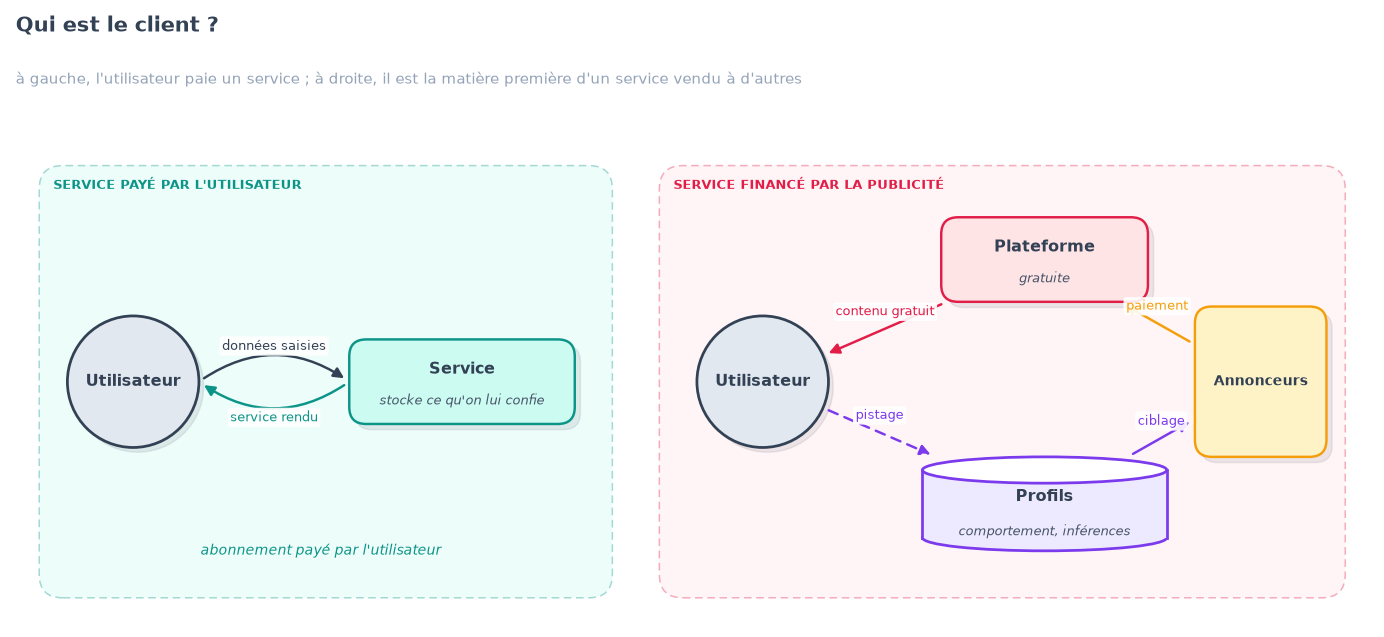

In [2]:
d = Diagram(14.5, 5.6, title="Qui est le client ?",
            subtitle="à gauche, l'utilisateur paie un service ; à droite, il est la matière première d'un service vendu à d'autres")
d.group(0.3, 0.3, 6.4, 4.9, "service payé par l'utilisateur", color=TEAL)
d.box("u1", 1.3, 2.6, "Utilisateur", kind="user", w=1.4, color=SLATE)
d.box("s1", 4.8, 2.6, "Service", sub="stocke ce qu'on lui confie", color=TEAL, w=2.4)
d.arrow("u1", "s1", "données saisies", rad=-0.35, label_offset=(0, 0.1))
d.arrow("s1", "u1", "service rendu", rad=-0.35, color=TEAL, label_offset=(0, -0.1))
d.note(3.3, 0.8, "abonnement payé par l'utilisateur", color=TEAL)
d.group(6.9, 0.3, 14.2, 4.9, "service financé par la publicité", color=ROSE)
d.box("u2", 8.0, 2.6, "Utilisateur", kind="user", w=1.4, color=SLATE)
d.box("s2", 11.0, 3.9, "Plateforme", sub="gratuite", color=ROSE, w=2.2)
d.box("p2", 11.0, 1.3, "Profils", sub="comportement, inférences", color=VIOLET, kind="db", w=2.6, h=1.0)
d.box("a2", 13.3, 2.6, "Annonceurs", color=AMBER, w=1.4, h=1.6, fontsize=9)
d.arrow("s2", "u2", "contenu gratuit", color=ROSE)
d.arrow("u2", "p2", "pistage", style="dashed", color=VIOLET)
d.arrow("p2", "a2", "ciblage", color=VIOLET)
d.arrow("a2", "s2", "paiement", color=AMBER)
d.show()

> **À retenir.** La question décisive est « qui paie ? ». Quand ce sont les annonceurs,
> l'utilisateur n'est plus le client mais la source des données vendues, et le pistage
> tend à dépasser ce qui sert l'utilisateur.

## 2. Surveillance : l'anonymat est une illusion (sous-section *Surveillance*)

Le livre propose une expérience de pensée : remplacer le mot « données » par
« surveillance » dans les phrases habituelles du métier, et voir si elles sonnent
toujours aussi bien. Faisons-la.

In [3]:
phrases = ["Notre organisation pilotée par les données collecte des flux de données en temps réel "
           "et les range dans notre entrepôt de données.",
           "Nos data scientists exploitent les données avec des outils d'analyse avancés.",
           "Nous valorisons les données de nos utilisateurs pour en tirer de nouvelles connaissances."]
swap = [("les données", "la surveillance"), ("de données", "de surveillance"),
        ("data scientists", "scientifiques de la surveillance")]
for ph in phrases:
    for a, b in swap:
        ph = ph.replace(a, b)
    print(ph)

Notre organisation pilotée par la surveillance collecte des flux de surveillance en temps réel et les range dans notre entrepôt de surveillance.
Nos scientifiques de la surveillance exploitent la surveillance avec des outils d'analyse avancés.
Nous valorisons la surveillance de nos utilisateurs pour en tirer de nouvelles connaissances.


Le livre assume le ton polémique : en cherchant à faire « manger le monde » par le
logiciel, l'industrie a bâti la plus vaste infrastructure de surveillance de masse
jamais vue. Micros connectés partout (téléphones, télévisions, assistants vocaux,
babyphones, jouets), souvent mal sécurisés ; localisation, relations, achats, santé
enregistrés presque inévitablement. Une organisation peut finir par en savoir plus sur
une personne que cette personne elle-même, en détectant une maladie ou des difficultés
financières avant elle. Les régimes les plus répressifs du passé n'osaient pas rêver
d'un micro dans chaque pièce et d'un traceur dans chaque poche ; nous les acceptons
volontairement, parce que les services rendus sont grands et que la collecte est faite
par des entreprises plutôt que par des agences d'État.

« Je n'ai rien à cacher » : c'est l'argument de ceux qui sont alignés sur les
structures de pouvoir existantes et n'appartiennent à aucune minorité marginalisée ;
tout le monde n'a pas cette chance. Et l'usage commercial cesse d'être anodin quand il
conditionne une assurance ou un emploi (cours précédent). L'analyse peut aussi révéler
des choses étonnamment intimes : les capteurs de mouvement d'une montre connectée
suffisent à deviner, avec une bonne précision, ce que l'on tape au clavier, y compris
des mots de passe.

**« Mais les données sont anonymisées ! »** Retirer le nom ne rend pas anonyme. Trois
attributs banals, le code postal, la date de naissance et le sexe, appelés
**quasi-identifiants**, suffisent à isoler la plupart des gens : c'est ce qu'a montré
Latanya Sweeney à la fin des années 1990, en retrouvant le dossier médical d'un
gouverneur dans des données hospitalières « anonymes ». Vérifions-le sur notre
population fictive : 100 000 personnes, 400 codes postaux de tailles très inégales
(médiane 154 habitants), naissances entre 1940 et 2005.

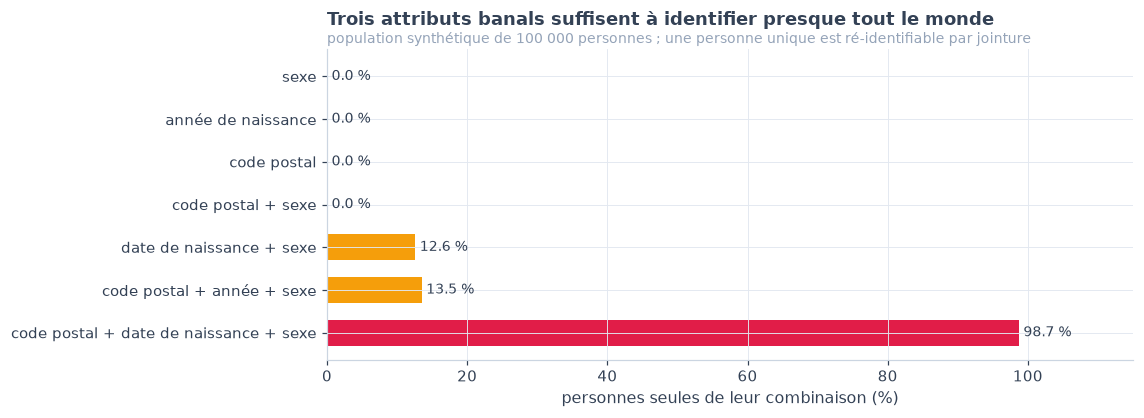

In [4]:
pop = et.make_population(100_000, n_zip=400, seed=0)
qi_sets = {"sexe": ["sex"], "année de naissance": ["year"], "code postal": ["zip"],
           "code postal + sexe": ["zip", "sex"], "date de naissance + sexe": ["birth", "sex"],
           "code postal + année + sexe": ["zip", "year", "sex"],
           "code postal + date de naissance + sexe": ["zip", "birth", "sex"]}
uniq = pd.Series({k: et.uniqueness(pop, v) * 100 for k, v in qi_sets.items()}, name="personnes uniques (%)")
fig, ax = plt.subplots(figsize=(10.5, 3.9))
ax.barh(uniq.index, uniq.values, color=[GRAY] * 4 + [AMBER, AMBER, ROSE], height=0.6)
annotate_bars(ax, "{:.1f} %")
ax.set_xlim(0, 115); ax.invert_yaxis()
ax.set_xlabel("personnes seules de leur combinaison (%)")
ax.set_title("Trois attributs banals suffisent à identifier presque tout le monde")
subtitle(ax, "population synthétique de 100 000 personnes ; une personne unique est ré-identifiable par jointure")
plt.tight_layout(); plt.show()

Chaque attribut isolé est inoffensif ; leur **combinaison** ne l'est pas : 98,7 % des
personnes sont seules à avoir leur code postal, leur date de naissance et leur sexe.
Le calcul l'explique : il y a $66 \times 365 \times 2 \approx 48\,000$ combinaisons
(date, sexe) possibles et seulement quelques centaines d'habitants par code postal. Si
$N$ personnes se répartissent uniformément sur $D$ combinaisons, la probabilité qu'une
personne soit seule vaut $(1 - 1/D)^{N-1} \approx e^{-N/D}$.

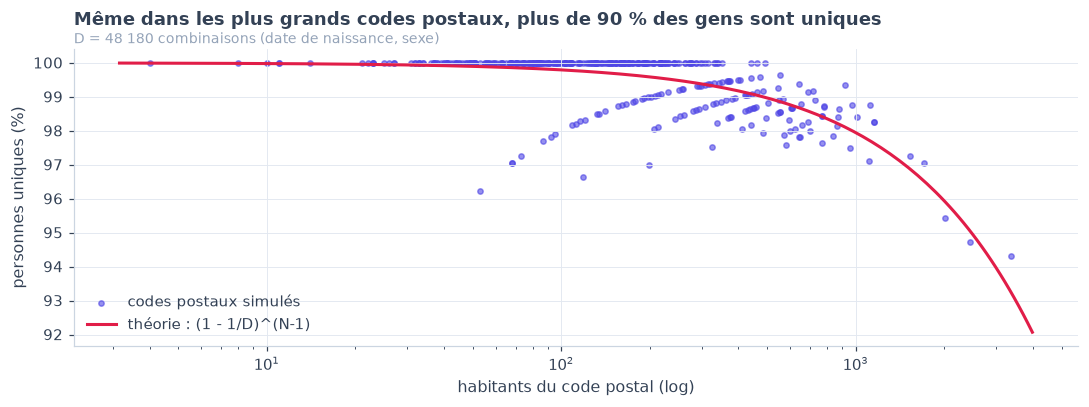

In [5]:
D = 66 * 365 * 2
by_zip = pop.assign(u=et.class_sizes(pop, ["zip", "birth", "sex"]) == 1).groupby("zip").agg(n=("u", "size"), u=("u", "mean"))
nn = np.logspace(0.5, 3.6, 200)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.scatter(by_zip["n"], by_zip["u"] * 100, s=12, color=INDIGO, alpha=0.6, label="codes postaux simulés")
ax.plot(nn, [et.expected_unique_fraction(x, D) * 100 for x in nn], color=ROSE, label="théorie : (1 - 1/D)^(N-1)")
ax.set_xscale("log")
ax.set_xlabel("habitants du code postal (log)"); ax.set_ylabel("personnes uniques (%)")
ax.set_title("Même dans les plus grands codes postaux, plus de 90 % des gens sont uniques")
subtitle(ax, "D = " + f"{D:,}".replace(",", " ") + " combinaisons (date de naissance, sexe)")
ax.legend()
plt.tight_layout(); plt.show()

**L'attaque par jointure.** Un hôpital publie 20 000 dossiers « anonymisés » (sans nom,
mais avec code postal, date de naissance, sexe et diagnostic). Une liste publique, par
exemple électorale, donne nom, code postal, date de naissance et sexe de 30 000
personnes. Il suffit d'une jointure SQL sur les trois colonnes.

In [6]:
pop["id"] = np.arange(len(pop))
released = pop.sample(20_000, random_state=1)[["zip", "birth", "sex", "condition", "id"]]
public = pop.sample(30_000, random_state=2)[["zip", "birth", "sex", "id"]]
qi = ["zip", "birth", "sex"]
n_rel = released.groupby(qi).size().rename("n_rel")
n_pub = public.groupby(qi).size().rename("n_pub")
j = (released.rename(columns={"id": "vrai_id"}).join(n_rel, on=qi).join(n_pub, on=qi)
     .merge(public.rename(columns={"id": "id_retrouve"}), on=qi, how="left"))
sure = j[(j["n_rel"] == 1) & (j["n_pub"] == 1)]
in_both = released["id"].isin(public["id"]).sum()
res = pd.Series({"dossiers publiés": len(released),
                 "dont personnes aussi dans la liste publique": in_both,
                 "ré-identifiés avec certitude (appariement unique)": len(sure),
                 "dont appariement correct (%)": (sure["vrai_id"] == sure["id_retrouve"]).mean() * 100,
                 "diagnostics sensibles révélés": int(sure["condition"].sum())})
res

dossiers publiés                                     20000.000
dont personnes aussi dans la liste publique           5968.000
ré-identifiés avec certitude (appariement unique)     5981.000
dont appariement correct (%)                            99.114
diagnostics sensibles révélés                          115.000
dtype: float64

Sur les quelque 6 000 dossiers dont la personne figure aussi dans la liste publique,
presque tous sont rattachés à un nom par un appariement unique, correct dans 99 % des
cas. Les 115 diagnostics sensibles parmi eux sont désormais attachés à un nom. Personne n'a « piraté » quoi que ce soit : on a seulement croisé deux jeux de
données, ce que les jeux de données dérivés des cours 1 à 5 de ce chapitre font en permanence.

**Généraliser pour protéger ?** La parade classique est le **k-anonymat** : généraliser
les quasi-identifiants (tronquer le code postal, ne garder que l'année ou la décennie
de naissance) jusqu'à ce que chaque combinaison soit partagée par au moins $k$
personnes. Mesurons le prix à payer.

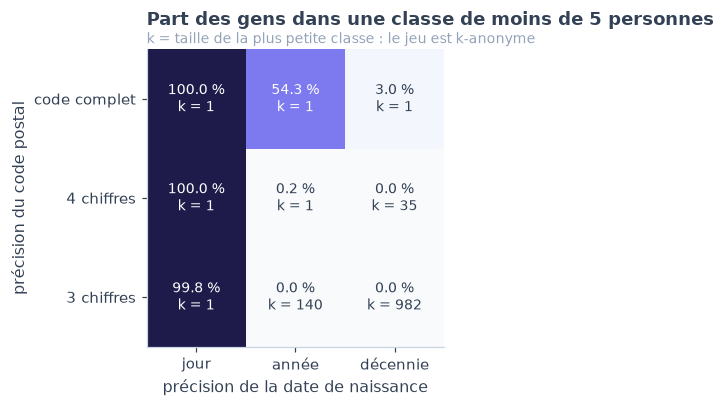

,code postal,naissance,uniques (%),k (plus petite classe),classes < 5 (% des gens)
0,code complet,jour,98.710,1,100.000
1,code complet,année,13.496,1,54.276
2,code complet,décennie,0.216,1,2.994
3,4 chiffres,jour,94.133,1,100.000
4,4 chiffres,année,0.001,1,0.187
5,4 chiffres,décennie,0.000,35,0.000
6,3 chiffres,jour,59.421,1,99.815
7,3 chiffres,année,0.000,140,0.000
8,3 chiffres,décennie,0.000,982,0.000


In [7]:
grid = []
for zd, zlabel in [(5, "code complet"), (4, "4 chiffres"), (3, "3 chiffres")]:
    for b, blabel in [("day", "jour"), ("year", "année"), ("decade", "décennie")]:
        g = et.generalize(pop, zd, b)
        grid.append({"code postal": zlabel, "naissance": blabel, "uniques (%)": et.uniqueness(g, qi) * 100,
                     "k (plus petite classe)": et.k_anonymity(g, qi),
                     "classes < 5 (% des gens)": (et.class_sizes(g, qi) < 5).mean() * 100})
G = pd.DataFrame(grid)
M = G.pivot(index="code postal", columns="naissance", values="classes < 5 (% des gens)").loc[
    ["code complet", "4 chiffres", "3 chiffres"], ["jour", "année", "décennie"]]
K = G.pivot(index="code postal", columns="naissance", values="k (plus petite classe)").loc[M.index, M.columns]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
im = ax.imshow(M.values, cmap="ddia_seq", vmin=0, vmax=100)
for i in range(3):
    for jj in range(3):
        ax.text(jj, i, f"{M.values[i, jj]:.1f} %\nk = {K.values[i, jj]}", ha="center", va="center", fontsize=9,
                color="white" if M.values[i, jj] > 50 else SLATE)
ax.set_xticks(range(3), M.columns); ax.set_yticks(range(3), M.index); ax.grid(False)
ax.set_xlabel("précision de la date de naissance"); ax.set_ylabel("précision du code postal")
ax.set_title("Part des gens dans une classe de moins de 5 personnes")
subtitle(ax, "k = taille de la plus petite classe : le jeu est k-anonyme")
plt.tight_layout(); plt.show()
G

Il faut tronquer le code postal à 4 chiffres (40 zones au lieu de 400 codes) et ne
garder que la décennie de naissance pour obtenir un jeu 35-anonyme ; avec l'année de
naissance, il reste des personnes isolées. Les données y ont perdu l'essentiel de leur
précision géographique et temporelle. Et le k-anonymat a des
failles connues : si les $k$ personnes d'une classe partagent le même diagnostic, le
diagnostic fuit quand même (attaque par homogénéité), et un attaquant qui dispose
d'autres sources peut réduire la classe. L'anonymisation robuste est un problème
difficile, et la plupart des jeux « anonymisés » ne le sont pas.

> **À retenir.** La surveillance commerciale est devenue presque inévitable, et la
> collecte de données, même « anonyme », expose les personnes : quelques attributs
> banals suffisent à ré-identifier presque tout le monde par simple jointure. Protéger
> par généralisation coûte cher en précision, et reste fragile.

## 3. Consentement et liberté de choix (sous-section *Consent and freedom of choice*)

On objectera que les utilisateurs **choisissent** ces services, acceptent les
conditions d'utilisation et la politique de confidentialité, et reçoivent un service
en échange de leurs données. Le livre démonte l'argument en plusieurs temps.

1. **Le pistage est-il nécessaire ?** Mesurer les clics sur les résultats améliore le
   moteur de recherche ; profiler pour la publicité sert surtout à payer le service.
2. **Le consentement est-il éclairé ?** La plupart des utilisateurs ignorent ce qu'ils
   fournissent et ce qu'on en fait ; les politiques de confidentialité obscurcissent
   plus qu'elles n'éclairent. Les jeux de données dérivés, qui croisent toute la base
   d'utilisateurs avec du pistage et des sources externes, sont précisément ce qu'un
   utilisateur ne peut pas comprendre.
3. **La relation est à sens unique** : pas de négociation, les termes sont fixés par le
   service.
4. **Les données d'un utilisateur parlent des autres**, qui n'ont rien accepté.

Illustrons le dernier point. Quand un utilisateur téléverse son carnet d'adresses, le
service apprend l'existence et les relations de **non-utilisateurs** : il peut leur
construire un « profil fantôme ». Sur un graphe social synthétique de 5 000 personnes
(graphe de Barabási-Albert, quelques personnes très connectées), on fait varier la part
de la population inscrite (`et.shadow_profiles`).

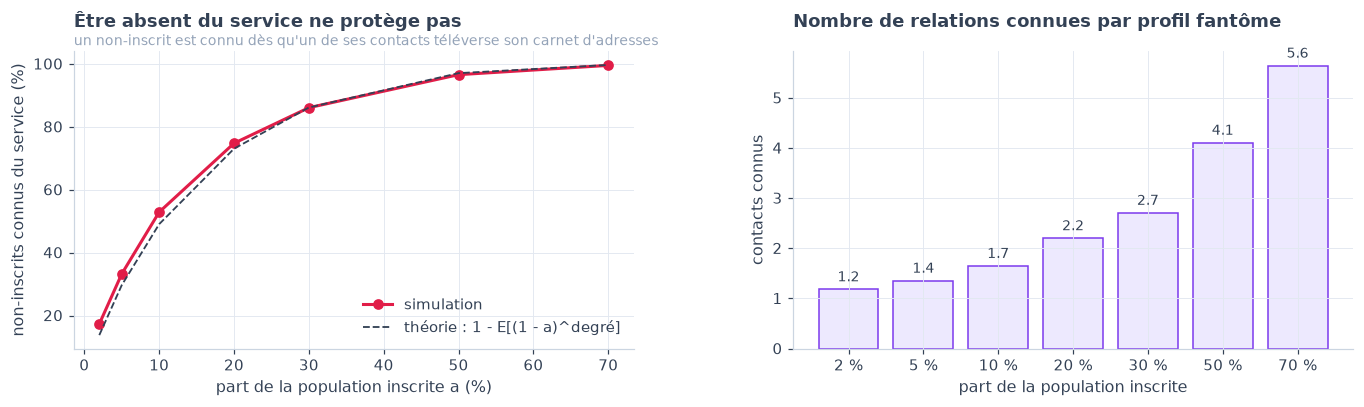

In [8]:
import networkx as nx

adoptions = np.array([0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7])
sim = np.array([et.shadow_profiles(n=5000, m=4, adoption=a, seed=0) for a in adoptions])
deg = np.array([dg for _, dg in nx.barabasi_albert_graph(5000, 4, seed=0).degree()])
theory = [1 - np.mean((1 - a) ** deg) for a in adoptions]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax = axes[0]
ax.plot(adoptions * 100, sim[:, 0] * 100, "o-", color=ROSE, label="simulation")
ax.plot(adoptions * 100, np.array(theory) * 100, "--", color=SLATE, lw=1.2, label="théorie : 1 - E[(1 - a)^degré]")
ax.set_xlabel("part de la population inscrite a (%)"); ax.set_ylabel("non-inscrits connus du service (%)")
ax.set_title("Être absent du service ne protège pas")
subtitle(ax, "un non-inscrit est connu dès qu'un de ses contacts téléverse son carnet d'adresses")
ax.legend()
ax = axes[1]
ax.bar([f"{a:.0%}".replace("%", " %") for a in adoptions], sim[:, 1], color=LIGHT[VIOLET], edgecolor=VIOLET)
annotate_bars(ax, "{:.1f}")
ax.set_xlabel("part de la population inscrite"); ax.set_ylabel("contacts connus")
ax.set_title("Nombre de relations connues par profil fantôme")
plt.tight_layout(); plt.show()

Avec seulement 10 % d'inscrits, le service connaît déjà plus de la moitié des
non-inscrits ; à 30 %, plus de 85 %. Le modèle théorique (chaque contact est inscrit
indépendamment avec probabilité $a$) colle à la simulation. Le consentement individuel
ne peut pas couvrir des données qui, par nature, concernent plusieurs personnes.

**Ne pas utiliser le service, un choix libre ?** Quand un service est devenu
indispensable à la vie sociale ou professionnelle, s'en passer a un coût réel, d'autant
plus élevé que l'effet de réseau est fort ; ces plateformes sont de plus conçues pour
capter l'attention, avec des mécaniques empruntées aux jeux d'argent. Refuser n'est une
option que pour ceux qui ont le temps, les connaissances et la position sociale pour
se le permettre. Pour les autres, la surveillance devient inévitable.

> **À retenir.** Le consentement par conditions d'utilisation est rarement éclairé,
> jamais négocié, et ne couvre pas les tiers dont parlent les données (profils
> fantômes). Quand un service est devenu incontournable, le refuser n'est pas un choix
> réellement libre.

## 4. Vie privée et usage des données (sous-section *Privacy and use of data*)

On entend que « la vie privée est morte », puisque tant de gens racontent leur vie sur
les réseaux sociaux. C'est un contresens : la vie privée n'est pas le secret absolu,
c'est la **liberté de choisir** ce que l'on révèle, à qui, et ce que l'on garde pour
soi. C'est un **droit de décision**. Une personne atteinte d'une maladie rare peut
vouloir partager son dossier avec des chercheurs, mais pas avec son assureur ou son
employeur.

Avec la collecte par surveillance, ce droit n'est pas détruit, il est **transféré** à
l'organisation qui collecte (« faites-nous confiance »). Elle garde secrets la plupart
des résultats de ses analyses (les révéler paraîtrait inquiétant et nuirait à son
modèle économique), et ne les dévoile qu'indirectement, sous forme d'outils de ciblage
publicitaire : « montrer cette annonce aux personnes atteintes de telle maladie ».

**Le ciblage révèle.** Combien de personnes reste-t-il quand on combine des critères
de ciblage anodins ? Prenons un code postal de taille moyenne dans notre population.

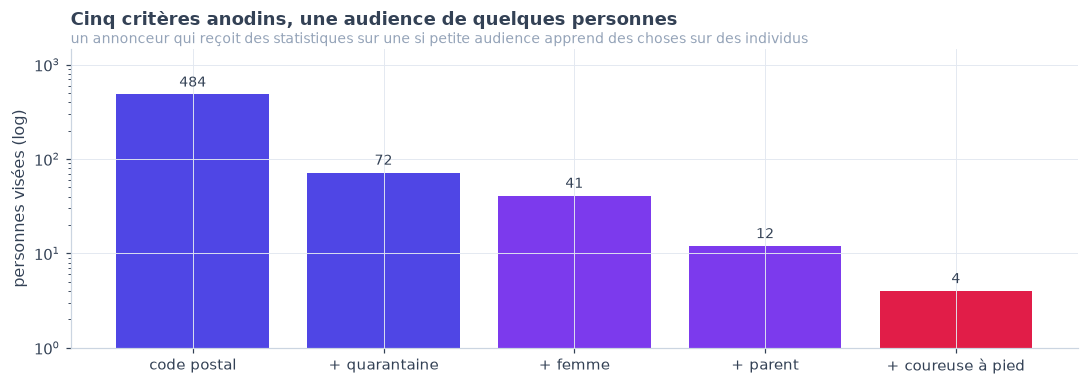

In [9]:
z = pop["zip"].value_counts().index[50]
steps = [("code postal", pop["zip"] == z)]
steps.append(("+ quarantaine", steps[-1][1] & (pop["age_band"] == 40)))
steps.append(("+ femme", steps[-1][1] & (pop["sex"] == 1)))
steps.append(("+ parent", steps[-1][1] & (pop["parent"] == 1)))
steps.append(("+ coureuse à pied", steps[-1][1] & (pop["runner"] == 1)))
sizes = pd.Series({k: int(m.sum()) for k, m in steps}, name="audience")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(sizes.index, sizes.values, color=[INDIGO, INDIGO, VIOLET, VIOLET, ROSE])
annotate_bars(ax, "{:.0f}")
ax.set_yscale("log"); ax.set_ylim(1, sizes.max() * 3)
ax.set_ylabel("personnes visées (log)")
ax.set_title("Cinq critères anodins, une audience de quelques personnes")
subtitle(ax, "un annonceur qui reçoit des statistiques sur une si petite audience apprend des choses sur des individus")
plt.tight_layout(); plt.show()

Quatre critères anodins réduisent un code postal de près de 500 habitants à 4 personnes.
Les plateformes imposent des tailles minimales d'audience, mais on les contourne en
comparant deux audiences qui ne diffèrent que d'une personne. Même sans ré-identifier
personne, les membres d'une audience ciblée sur une maladie ont perdu le contrôle de la
révélation de cette information : c'est l'entreprise, pas eux, qui exerce leur droit à
la vie privée, au service de son profit. Les paramètres de confidentialité ne règlent
que ce que voient **les autres utilisateurs** ; le service, lui, garde un accès total.

**Rendre le droit de décision : la réponse randomisée.** Il existe des techniques pour
apprendre des statistiques utiles sans apprendre la vérité sur chaque individu. La plus
ancienne (Warner, 1965) : à la question sensible, chacun répond la vérité avec
probabilité $p$, sinon il tire à pile ou face. Chaque réponse est niable ; la
proportion réelle $\pi$ se retrouve pourtant, car la proportion de « oui » vaut
$\lambda = p\,\pi + (1-p)/2$, d'où $\hat\pi = (\hat\lambda - (1-p)/2)/p$, de variance
$\lambda(1-\lambda)/(n p^2)$.

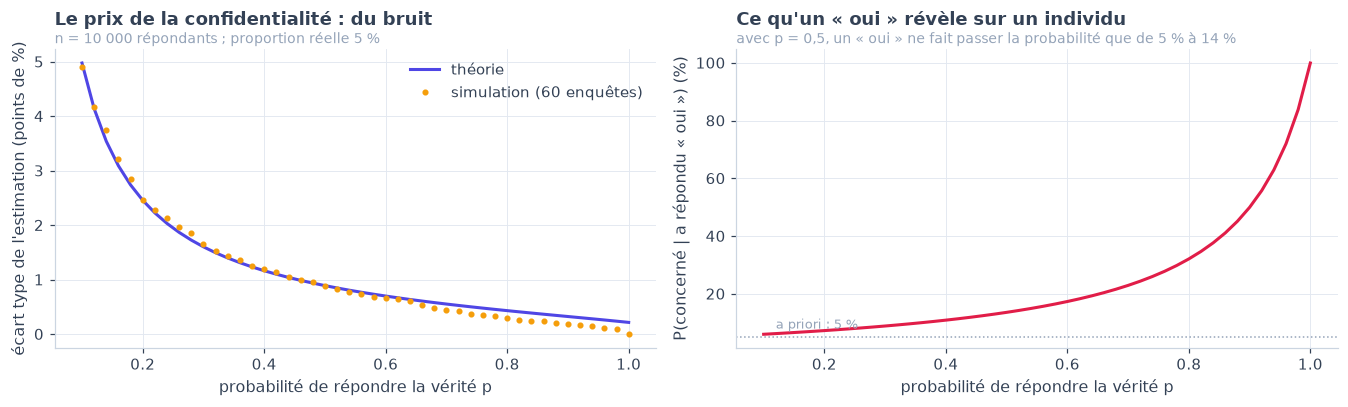

In [10]:
pi_true, n_resp = 0.05, 10_000
truth = (rng.random(n_resp) < pi_true).astype(int)
ps = np.linspace(0.1, 1, 46)
sim_err = []
for p_ in ps:
    ests = [et.rr_estimate(et.randomized_response(truth, p_, np.random.default_rng(1000 + s)), p_)
            for s in range(60)]
    sim_err.append(np.std(ests))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax = axes[0]
ax.plot(ps, [np.sqrt(et.rr_variance(pi_true, p_, n_resp)) * 100 for p_ in ps], color=INDIGO, label="théorie")
ax.plot(ps, np.array(sim_err) * 100, "o", ms=3, color=AMBER, label="simulation (60 enquêtes)")
ax.set_xlabel("probabilité de répondre la vérité p"); ax.set_ylabel("écart type de l'estimation (points de %)")
ax.set_title("Le prix de la confidentialité : du bruit")
subtitle(ax, "n = 10 000 répondants ; proportion réelle 5 %")
ax.legend()
ax = axes[1]
ax.plot(ps, [et.rr_posterior_yes(pi_true, p_) * 100 for p_ in ps], color=ROSE)
ax.axhline(pi_true * 100, color=GRAY, ls=":", lw=1)
ax.text(0.12, pi_true * 100 + 3, "a priori : 5 %", fontsize=8.5, color=GRAY)
ax.set_xlabel("probabilité de répondre la vérité p")
ax.set_ylabel("P(concerné | a répondu « oui ») (%)")
ax.set_title("Ce qu'un « oui » révèle sur un individu")
subtitle(ax, "avec p = 0,5, un « oui » ne fait passer la probabilité que de 5 % à 14 %")
plt.tight_layout(); plt.show()

La simulation suit la formule ; pour $p$ proche de 1 elle passe un peu en dessous,
parce que la formule compte aussi l'aléa du tirage des répondants, alors qu'on a gardé
ici la même population. Avec $p = 0{,}5$, l'enquêteur estime encore la proportion
avec un écart type inférieur à un point (0,9 point pour 10 000 réponses), mais un « oui » individuel ne
fait passer la probabilité d'être concerné que de 5 % à 14 % : la personne garde un
**déni plausible**. Ce compromis entre utilité statistique et protection individuelle
est l'idée de base de la confidentialité différentielle, sur laquelle reposent des
collectes de statistiques à grande échelle.

> **À retenir.** La vie privée est un droit de choisir ce que l'on révèle, pas le secret
> total. La collecte par surveillance transfère ce droit à l'entreprise, qui l'exerce à
> son profit, par exemple via le ciblage publicitaire. Des techniques comme la réponse
> randomisée montrent qu'on peut apprendre sur une population sans tout apprendre sur
> chacun.

## 5. Les données, un actif toxique et une source de pouvoir (sous-section *Data as assets and power*)

On parle parfois de « data exhaust », les gaz d'échappement des données, comme d'un
déchet sans valeur que l'analytique recyclerait. Le livre propose de renverser la
perspective : si la publicité ciblée finance le service, l'activité des utilisateurs
est une forme de **travail**, et l'application n'est qu'un appât. Les données
personnelles sont un actif : des courtiers de données les achètent, les agrègent et
les revendent dans l'ombre ; les jeunes pousses sont valorisées au nombre
d'utilisateurs, c'est-à-dire à leur capacité de surveillance.

Parce qu'elles ont de la valeur, tout le monde les veut : les entreprises, mais aussi
les gouvernements (accords secrets, contrainte légale, vol), les criminels, les
employés indélicats, le repreneur d'une entreprise en faillite. D'où l'image d'un
**actif toxique**, d'un matériau dangereux, d'un « nouvel uranium » plutôt que d'un
nouveau pétrole : chaque collecte doit mettre en balance le bénéfice et le risque que
les données tombent entre de mauvaises mains.

**La durée de conservation est un multiplicateur de risque.** Un service collecte
10 000 enregistrements par jour ; une fuite survient en moyenne tous les 5 ans et
emporte tout ce qui est conservé à ce moment-là (`et.breach_exposure`, 10 ans
simulés).

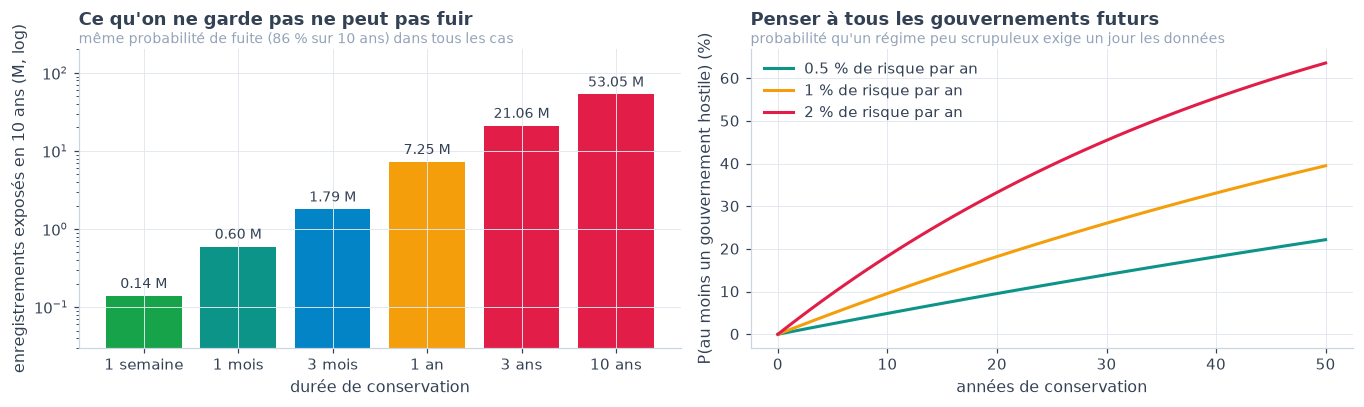

,exposés (moyenne),exposés (p95),P(au moins une fuite)
1 semaine,1.390e+05,3.500e+05,0.863
1 mois,5.955e+05,1.500e+06,0.863
3 mois,1.786e+06,4.500e+06,0.863
1 an,7.245e+06,1.825e+07,0.863
3 ans,2.106e+07,4.745e+07,0.863
10 ans,5.305e+07,7.300e+07,0.863


In [11]:
ret = np.array([7, 30, 90, 365, 3 * 365, 10 * 365])
rows = [et.breach_exposure(r, records_per_day=10_000, breaches_per_year=0.2, years=10, seed=0) for r in ret]
E = pd.DataFrame(rows, columns=["exposés (moyenne)", "exposés (p95)", "P(au moins une fuite)"],
                 index=["1 semaine", "1 mois", "3 mois", "1 an", "3 ans", "10 ans"])
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
ax = axes[0]
ax.bar(E.index, E["exposés (moyenne)"] / 1e6, color=[GREEN, TEAL, SKY, AMBER, ROSE, ROSE])
annotate_bars(ax, "{:.2f} M")
ax.set_yscale("log"); ax.set_ylim(0.03, 200)
ax.set_xlabel("durée de conservation"); ax.set_ylabel("enregistrements exposés en 10 ans (M, log)")
ax.set_title("Ce qu'on ne garde pas ne peut pas fuir")
subtitle(ax, f"même probabilité de fuite ({E['P(au moins une fuite)'].iloc[0]:.0%} sur 10 ans) dans tous les cas".replace("%", " %"))
ax = axes[1]
T = np.arange(0, 51)
for q, c in [(0.005, TEAL), (0.01, AMBER), (0.02, ROSE)]:
    ax.plot(T, (1 - (1 - q) ** T) * 100, color=c, label=f"{q * 100:g} % de risque par an")
ax.set_xlabel("années de conservation"); ax.set_ylabel("P(au moins un gouvernement hostile) (%)")
ax.set_title("Penser à tous les gouvernements futurs")
subtitle(ax, "probabilité qu'un régime peu scrupuleux exige un jour les données")
ax.legend()
plt.tight_layout(); plt.show()
E

La probabilité d'au moins une fuite en 10 ans est la même quelle que soit la durée de
conservation (environ 86 %), mais l'ampleur ne l'est pas : conserver une semaine
expose en moyenne 0,14 million d'enregistrements, conserver dix ans plus de 50 millions,
près de 400 fois plus. Le second graphique formalise une
remarque du livre : en collectant, il faut penser non seulement au contexte politique
actuel, mais à **tous les gouvernements futurs** ; avec 1 % de risque par an, la
probabilité qu'un régime hostile accède un jour à des données conservées 30 ans dépasse
25 %. Bruce Schneier y voit une affaire d'hygiène civique : on n'installe pas des
technologies qui faciliteraient un jour un État policier.

Savoir, c'est pouvoir ; observer les autres en échappant soi-même à l'observation est
l'une des formes les plus importantes du pouvoir. Les entreprises technologiques ne
cherchent pas le pouvoir politique, mais les connaissances accumulées, souvent à
l'insu de tous et hors de tout contrôle public, leur en donnent beaucoup sur nos vies.

> **À retenir.** Les données personnelles sont un actif convoité, donc un risque :
> fuites, contrainte légale, changement de régime. L'exposition croît avec la quantité
> collectée et la durée de conservation ; la meilleure protection est de ne pas
> collecter, ou de purger tôt.

## 6. Se souvenir de la révolution industrielle (sous-section *Remembering the Industrial Revolution*)

Les données sont la marque de l'ère de l'information, comme la machine à vapeur celle de
l'ère industrielle. La révolution industrielle a apporté une croissance durable et une
élévation du niveau de vie, mais aussi une pollution effroyable de l'air et de l'eau,
des logements insalubres, des journées interminables, le travail des enfants dans les
mines. Il a fallu longtemps pour imposer des garde-fous : normes environnementales,
sécurité au travail, interdiction du travail des enfants, inspection sanitaire des
aliments. Faire des affaires est devenu plus cher, et la société dans son ensemble y a
énormément gagné.

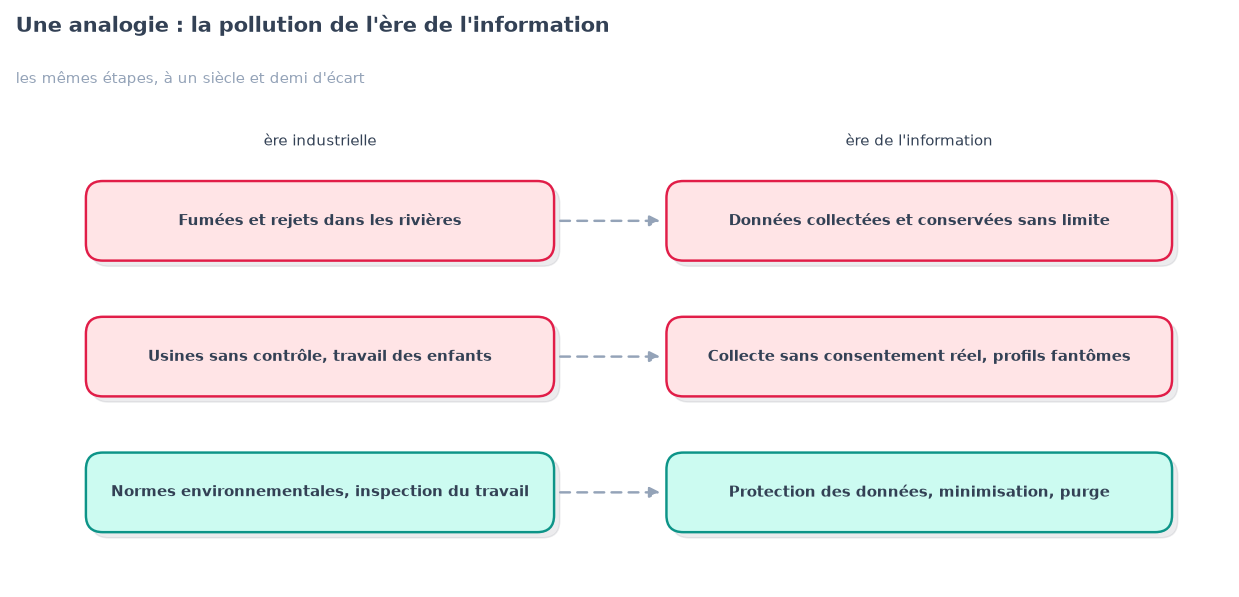

In [12]:
d = Diagram(13, 5.2, title="Une analogie : la pollution de l'ère de l'information",
            subtitle="les mêmes étapes, à un siècle et demi d'écart")
rows = [("Fumées et rejets dans les rivières", "Données collectées et conservées sans limite"),
        ("Usines sans contrôle, travail des enfants", "Collecte sans consentement réel, profils fantômes"),
        ("Normes environnementales, inspection du travail", "Protection des données, minimisation, purge")]
for i, (a, b) in enumerate(rows):
    y = 3.9 - i * 1.45
    col = ROSE if i < 2 else TEAL
    d.box(f"a{i}", 3.3, y, a, color=col, w=5.0, h=0.85, fontsize=9.5)
    d.box(f"b{i}", 9.7, y, b, color=col, w=5.4, h=0.85, fontsize=9.5)
    d.arrow(f"a{i}", f"b{i}", color=GRAY, style="dashed")
d.note(3.3, 4.75, "ère industrielle", color=SLATE, fontsize=10, style="normal")
d.note(9.7, 4.75, "ère de l'information", color=SLATE, fontsize=10, style="normal")
d.show()

Le livre cite Bruce Schneier, pour qui les données sont le problème de pollution de
l'ère de l'information et la protection de la vie privée son défi environnemental : de
même que nous nous demandons comment nos ancêtres ont pu ignorer la pollution, nos
petits-enfants nous jugeront sur la manière dont nous aurons traité la collecte et
l'abus de données.

> **À retenir.** Comme l'industrialisation, l'informatisation apporte d'immenses
> bénéfices et des dégâts qu'il faut apprendre à contenir. Les garde-fous coûtent, mais
> l'histoire montre que la société y gagne.

## 7. Législation et autorégulation (sous-section *Legislation and self-regulation*)

Les lois de protection des données peuvent aider. En Europe, la directive de 1995 sur la
protection des données pose déjà deux principes : des données collectées pour des
**finalités déterminées, explicites et légitimes**, et non traitées ensuite de façon
incompatible avec elles ; des données **adéquates, pertinentes et non excessives** au
regard de ces finalités. Ce principe de **minimisation** va frontalement à l'encontre
de la philosophie du big data : tout collecter, tout croiser, explorer pour découvrir
des usages imprévus, c'est-à-dire exactement le contraire de finalités « déterminées et
explicites ». Le livre doute que ces textes, souvent anciens et peu appliqués,
changent les pratiques à eux seuls.

**La minimisation en pratique.** Concrètement, minimiser c'est attacher à chaque
donnée une finalité et une durée de conservation, et purger. Un petit catalogue :

In [13]:
catalog = pd.DataFrame([
    ("adresse e-mail", "compte, facturation", "durée du compte"),
    ("historique d'achats", "facturation, garantie", "5 ans (obligation comptable)"),
    ("clics sur les résultats", "amélioration du classement", "90 jours, puis agrégats anonymes"),
    ("localisation précise", "livraison en cours", "24 heures"),
    ("contacts du carnet d'adresses", "aucune finalité nécessaire", "ne pas collecter"),
], columns=["donnée", "finalité", "conservation"]).set_index("donnée")
catalog

,finalité,conservation
donnée,,
adresse e-mail,"compte, facturation",durée du compte
historique d'achats,"facturation, garantie",5 ans (obligation comptable)
clics sur les résultats,amélioration du classement,"90 jours, puis agrégats anonymes"
localisation précise,livraison en cours,24 heures
contacts du carnet d'adresses,aucune finalité nécessaire,ne pas collecter


Simulons l'effet d'une purge sur trois ans pour les journaux de clics : 50 000 nouveaux
enregistrements par jour, conservés indéfiniment ou purgés après 90 jours (les
statistiques utiles au classement sont conservées sous forme agrégée).

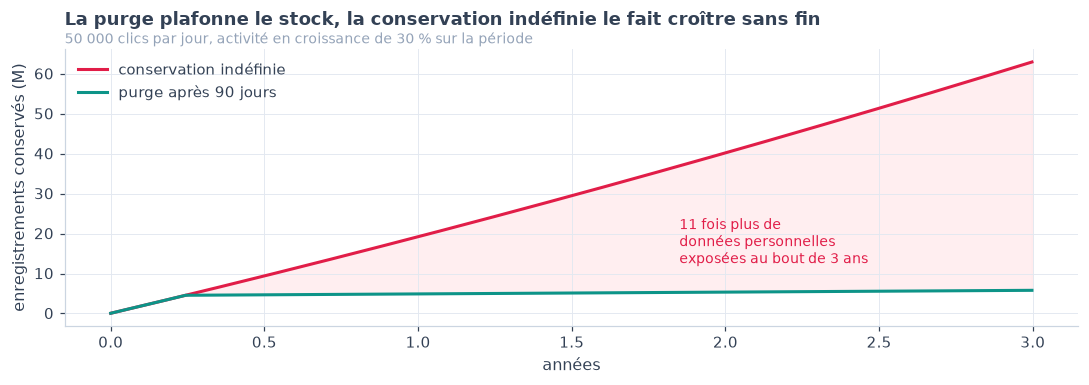

In [14]:
days = np.arange(3 * 365)
daily = 50_000 * (1 + 0.3 * days / days[-1])            # croissance de l'activité
stock_inf = np.cumsum(daily)
stock_90 = np.array([daily[max(0, t - 89):t + 1].sum() for t in days])
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(days / 365, stock_inf / 1e6, color=ROSE, label="conservation indéfinie")
ax.plot(days / 365, stock_90 / 1e6, color=TEAL, label="purge après 90 jours")
ax.fill_between(days / 365, stock_90 / 1e6, stock_inf / 1e6, color=LIGHT[ROSE], alpha=0.6)
ax.text(1.85, stock_inf[-1] / 1e6 * 0.2, f"{stock_inf[-1] / stock_90[-1]:.0f} fois plus de\ndonnées personnelles\nexposées au bout de 3 ans",
        fontsize=9, color=ROSE)
ax.set_xlabel("années"); ax.set_ylabel("enregistrements conservés (M)")
ax.set_title("La purge plafonne le stock, la conservation indéfinie le fait croître sans fin")
subtitle(ax, "50 000 clics par jour, activité en croissance de 30 % sur la période")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

**Autorégulation et culture.** Les entreprises qui collectent beaucoup de données
s'opposent généralement à la régulation, au nom de l'innovation, et elles n'ont pas
entièrement tort : partager des données médicales comporte des risques, mais pourrait
aussi sauver des vies grâce à de meilleurs diagnostics. Trouver l'équilibre est
difficile. Le livre appelle surtout à un **changement de culture** :

- cesser de voir les utilisateurs comme des métriques à optimiser, se souvenir que ce
  sont des humains qui méritent respect, dignité et autonomie ;
- s'autoréguler pour mériter la confiance des gens qui dépendent de nos logiciels, et
  leur expliquer comment leurs données sont utilisées ;
- laisser à chacun le contrôle de ses données, comme on protège un parc national : sans
  protection explicite, ce bien commun sera détruit ;
- **ne pas tout conserver indéfiniment**, purger dès que les données ne servent plus, et
  minimiser la collecte dès le départ : des données que l'on n'a pas ne peuvent être ni
  volées, ni divulguées, ni réclamées par un gouvernement.

> **À retenir.** La loi pose des principes (finalité, minimisation) qui contredisent la
> logique « tout collecter » ; elle ne suffit pas sans un changement de culture des
> ingénieurs. Concrètement : une finalité et une durée pour chaque donnée, des purges
> automatiques, et la question « en a-t-on vraiment besoin ? » avant chaque collecte.

## Synthèse

- Quand le service vit de la publicité, l'utilisateur n'est plus le client : le pistage
  devient surveillance.
- L'anonymisation par suppression du nom est illusoire : code postal, date de naissance
  et sexe isolent presque tout le monde ; le k-anonymat coûte cher en précision.
- Le consentement par conditions d'utilisation est rarement éclairé et ne couvre pas les
  tiers (profils fantômes) ; renoncer à un service incontournable n'est pas un choix libre.
- La vie privée est un droit de décider ce que l'on révèle ; la surveillance le
  transfère à l'entreprise. La réponse randomisée montre qu'on peut apprendre sur une
  population en laissant à chacun un déni plausible.
- Les données sont un actif toxique : l'exposition croît avec la collecte et la durée de
  conservation ; minimiser et purger sont les meilleures défenses.

Cette section clôt le livre. Les outils des chapitres précédents (journaux d'événements,
données dérivées, traitements par lots et en flux, chapitres 10 à 12)
sont d'une puissance considérable : ils servent aussi bien à rendre service qu'à
surveiller. À nous, ingénieurs, de les mettre au service d'un monde qui traite les gens
avec humanité et respect.